# DALI prefiltering on AlphaFoldDB (Fig. 4, panels a–e)

73 SCOPe multidomain proteins were searched with Foldseek against 2,027,033 AlphaFoldDB
structures (the benchmark of Barrio-Hernandez et al.). Each hit carries Foldseek's bit
score and E-value, plus an SG p-value from 50 seeded decoys per query. Decoys are 3Di and
amino acids shuffled with independent first-order Markov chains. The decoys were searched
with `--alignment-type 2 --no-rev-align 1 --comp-bias-corr 0 --gap-open 2`.

DALI provides the ground truth. A hit is **DALI-supported** when its DALI Z-score reaches
the query's own threshold Z′, the elbow of that query's DALI Z curve. At the same
numerical cutoff, SG p-values recover more DALI-supported matches than E-values.

| Panel | Content |
|---|---|
| a | DALI-supported matches per query |
| b | the same matches binned by how far DALI Z exceeds the threshold, ΔZ = Z − Z′ |
| c | mean identified matches per query vs cutoff, with pointwise 95% bootstrap CI (10,000 resamples of queries) |
| d | identified matches vs cutoff for one query (1h5wA) |
| e | that query's matches found only by the SG p-value at cutoff 0.01: SG p-value vs E-value per target |

| Step | What | Output in `results/dali_prefiltering/fig4/` |
|---|---|---|
| 1 | per-query tables from the search results | `query_summary.csv`, `curves.csv.gz`, `sg_only_0p01.csv` |
| 2 | load or calculate mean recovery curves with bootstrap CIs | `fig4_c_aggregate_curve.csv`, `fig4_c_paired_difference.csv` |
| 3 | individual panels a–e | `fig4_a.pdf` / `.png` through `fig4_e.pdf` / `.png` |
| 4 | the values plotted in each panel | `fig4_<panel>.csv` |

**Before you start:** from Zenodo, unpack `results_dali_prefiltering.tar.gz` at the
repository root. This gives `results/dali_prefiltering/per_query/<query>.tsv.gz`. Each per-query
file has one row per target, with these columns:

| Column | Meaning |
|---|---|
| `query`, `target` | protein IDs |
| `bits`, `evalue` | Foldseek bit score and E-value |
| `sgpval` | SG p-value |
| `dali_Z` | DALI Z-score, if DALI reported the pair |
| `Zprime` | the query's threshold Z′ |
| `label_ge_Zprime` | 1 if the target is DALI-supported |

The search inputs (query structures, the AlphaFoldDB subset database and the query
list with each threshold Z′) are in `data_dali_prefiltering.tar.gz`; this notebook doesn't need them.
With `CACHE = True` (the default), existing summary and bootstrap tables are loaded
directly. Missing tables are calculated from the per-query results and saved. No
Foldseek or DALI search is run. Set `CACHE = False` to rebuild all analysis tables;
reading about 111 million rows takes a few minutes and the bootstrap takes about 20 s.
Rebuild after changing the inputs, `CUTOFF`, or bootstrap settings. Run this notebook
from `tutorial/` or the repository root.

## Parameters and style

In [1]:
from pathlib import Path
import os
if not Path('scripts/build.sh').exists():   # opened from tutorial/: work from the repository root
    os.chdir('..')
ROOT = Path('.')                            # all paths below are relative to the repository root

DATA      = ROOT / 'results/dali_prefiltering'
PER_QUERY = DATA / 'per_query'              # <query>.tsv.gz from Zenodo
OUT       = DATA / 'fig4'                   # tables and figure written here

EXAMPLE = '1h5wA'    # query shown in panels d and e
CUTOFF  = 0.01       # cutoff for the per-query counts and panel e
CACHE   = True       # True = reuse analysis tables; False = rebuild from per-query results

In [2]:
from pathlib import Path
import logging, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator, MaxNLocator, StrMethodFormatter
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

GOLD, GOLD_EDGE, DARK, INK, MUTED = '#D9A61D', '#9B7310', '#3E4146', '#202329', '#676B71'
METRICS = ['evalue', 'sgpval']
LABELS = {'evalue': 'E-value', 'sgpval': 'SG p-value'}
TICKS = np.array([1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1])
LOW, HIGH = 1e-8, .1
SEED, REPLICATES = 20261016, 10000
COUNT_COLS = [f'margin_bin_{i}_count' for i in range(5)]
BIN_LABELS = ['[0, 1)', '[1, 2)', '[2, 5)', '[5, 10)', '≥10']


def pick_font():
    for d in [Path('/System/Library/Fonts/Supplemental'), Path('/Library/Fonts'), Path.home() / 'Library/Fonts']:
        for name in ['Arial.ttf', 'Arial Bold.ttf', 'Arial Italic.ttf']:
            if (d / name).exists():
                font_manager.fontManager.addfont(str(d / name))
    for family in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']:
        try:
            font_manager.findfont(family, fallback_to_default=False); return family
        except ValueError:
            continue
    return 'DejaVu Sans'


FONT = pick_font()


def style():
    plt.rcdefaults()
    plt.rcParams.update({'font.family': FONT, 'font.size': 7, 'axes.linewidth': .6, 'axes.edgecolor': DARK,
        'text.color': INK, 'axes.labelcolor': INK, 'xtick.color': DARK, 'ytick.color': DARK,
        'xtick.major.width': .5, 'ytick.major.width': .5, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
        'axes.grid': False, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
        'axes.unicode_minus': False, 'figure.facecolor': 'white', 'savefig.facecolor': 'white',
        'path.simplify': False, 'mathtext.fontset': 'custom', 'mathtext.rm': FONT,
        'mathtext.it': f'{FONT}:italic', 'mathtext.bf': f'{FONT}:bold', 'mathtext.default': 'regular'})


def boxed(ax):
    for sp in ax.spines.values(): sp.set_visible(True)
    ax.tick_params(top=False, right=False)

style()
print('Font family:', FONT)

Font family: Arial


## 1. Per-query tables from the search results

For each query, and for each score (E-value and SG p-value), the steps are:
- **Ranking.** Hits are ranked in ascending order. A hit is selected when its value is
  ≤ the cutoff, and equal scores are always admitted together.
- **Curves.** The curve stores the number of DALI-supported hits selected at every cutoff
  ≤ 0.1 where that number changes.
- **Per-query counts.** These are the number of DALI-supported matches and their ΔZ bins.
- **Counts at `CUTOFF`.** The table records hits found by each score, label-negative hits,
  and matches found by only one of the two scores.

In [3]:
QUERY_COLS = ['query', 'target', 'evalue', 'sgpval', 'dali_Z', 'Zprime', 'label_ge_Zprime']
MARGIN_EDGES = [0, 1, 2, 5, 10, np.inf]


def summarize_query(path):
    d = pd.read_csv(path, sep='\t', usecols=QUERY_COLS, float_precision='round_trip')
    q = d['query'].iat[0]
    y = d.label_ge_Zprime.to_numpy(dtype=np.int64)
    pos = y == 1
    zprime = float(d.Zprime.iat[0])
    margin = np.round(d.dali_Z.to_numpy()[pos] - zprime, 10)
    row = dict(query=q, rows=len(d), positive_total=int(pos.sum()), zprime=zprime,
               **{c: int(v) for c, v in zip(COUNT_COLS, np.histogram(margin, MARGIN_EDGES)[0])})

    curves = []
    for m in METRICS:
        s = d[m].to_numpy()
        order = np.argsort(s, kind='stable')
        scores, cum = s[order], np.cumsum(y[order])
        ends = np.r_[np.flatnonzero(np.diff(scores) != 0), len(s) - 1]   # last row of each tied group
        tp, cut = cum[ends], scores[ends]
        keep = (tp != np.r_[0, tp[:-1]]) & (cut <= HIGH)                 # count changes, cutoff <= 0.1
        curves.append(pd.DataFrame(dict(query=q, metric=m, cutoff=cut[keep], true_hits=tp[keep])))

    e_sel, s_sel = d.evalue.le(CUTOFF).to_numpy(), d.sgpval.le(CUTOFF).to_numpy()
    row.update(e_true_hits=int((e_sel & pos).sum()), sg_true_hits=int((s_sel & pos).sum()),
               e_label_negative=int((e_sel & ~pos).sum()), sg_label_negative=int((s_sel & ~pos).sum()),
               shared_true_hits=int((e_sel & s_sel & pos).sum()),
               sg_only_true_hits=int((s_sel & ~e_sel & pos).sum()),
               e_only_true_hits=int((e_sel & ~s_sel & pos).sum()))
    sg_only = (d[pos & s_sel & ~e_sel].sort_values(['dali_Z', 'target'], ascending=[False, True])
               [['query', 'target', 'dali_Z', 'Zprime', 'evalue', 'sgpval', 'label_ge_Zprime']])
    return row, pd.concat(curves, ignore_index=True), sg_only


OUT.mkdir(parents=True, exist_ok=True)
outputs = [OUT / 'query_summary.csv', OUT / 'curves.csv.gz', OUT / 'sg_only_0p01.csv']
if not CACHE or not all(p.exists() for p in outputs):
    files = sorted(PER_QUERY.glob('*.tsv.gz'))
    assert files, f'no per-query results in {PER_QUERY}: unpack results_dali_prefiltering.tar.gz from Zenodo'
    t = time.time(); rows, curve_parts, sg_parts = [], [], []
    for f in files:
        r, c, s = summarize_query(f)
        rows.append(r); curve_parts.append(c); sg_parts.append(s)
    pd.DataFrame(rows).to_csv(outputs[0], index=False)
    pd.concat(curve_parts, ignore_index=True).to_csv(outputs[1], index=False)
    pd.concat(sg_parts, ignore_index=True).to_csv(outputs[2], index=False)
    print(f'{len(files)} queries, {sum(r["rows"] for r in rows):,} rows summarized in {time.time() - t:.0f}s')
    rebuilt_summaries = True
else:
    print('Loading cached per-query summary tables from', OUT)
    rebuilt_summaries = False

meta = pd.read_csv(outputs[0])
curves = pd.read_csv(outputs[1], float_precision='round_trip')
sg_only = pd.read_csv(outputs[2], float_precision='round_trip')
QUERIES = meta['query'].tolist()
all_curves = {q: {m: curves[(curves['query'] == q) & (curves.metric == m)].reset_index(drop=True)
                  for m in METRICS} for q in QUERIES}
atlas = (meta.rename(columns={'positive_total': 'label_positive', 'zprime': 'Zprime'})
         .sort_values(['label_positive', 'query'], ascending=[False, True])
         [['query', 'label_positive', 'Zprime', *COUNT_COLS]].reset_index(drop=True))
rescued = sg_only[sg_only['query'].eq(EXAMPLE)].reset_index(drop=True)
print(f'{len(QUERIES)} queries, {atlas.label_positive.sum():,} DALI-supported matches; '
      f'{len(rescued)} SG-only matches for {EXAMPLE} at {CUTOFF}')
meta

Loading cached per-query summary tables from results/dali_prefiltering/fig4
73 queries, 279,412 DALI-supported matches; 23 SG-only matches for 1h5wA at 0.01


,query,rows,positive_total,zprime,margin_bin_0_count,margin_bin_1_count,margin_bin_2_count,margin_bin_3_count,margin_bin_4_count,e_true_hits,sg_true_hits,e_label_negative,sg_label_negative,shared_true_hits,sg_only_true_hits,e_only_true_hits
0,1a4eA,1686735,201,5.3,69,10,24,23,75,115,121,8,28,115,6,0
1,1cc1L,1535011,196,6.5,93,13,22,18,50,70,83,9,16,70,13,0
2,1cc1S,980235,721,5.4,586,41,53,13,28,76,100,7,7,76,24,0
3,1d3yA,1481990,2758,5.5,2065,368,176,82,67,156,174,7,4,155,19,1
4,1dd9A,1452262,1803,5.0,952,233,200,280,138,445,460,11,10,439,21,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,4dynA,1578822,1671,4.0,1607,60,1,1,2,2,2,0,0,2,0,0
69,4ogcA,1798474,9216,4.9,4975,2469,1702,66,4,53,49,0,0,35,14,18
70,4wsbC,1783523,6895,3.3,6280,559,55,1,0,1,1,0,0,1,0,0
71,5d9aA,1840423,9106,3.5,8197,756,152,1,0,0,0,5,0,0,0,0


## 2. Mean recovery curves from cached tables

Panel c averages the curves over all queries with equal weight, including queries
with no hit at any cutoff ≤ 0.1. Shading is a pointwise 95% percentile-bootstrap CI.
Each of the 10,000 replicates resamples whole queries with replacement (seed 20261016),
keeping both scores of a query together. Existing aggregate CSVs are loaded when
`CACHE = True`; otherwise the bootstrap is calculated and saved. The checks below
validate consistency between the loaded tables without hardcoded reference results.


In [4]:
def sample(frame, x, column='true_hits'):
    """Right-continuous step lookup: value at the last cutoff <= x (0 before the first)."""
    if len(frame) == 0:                       # 1knzA, 1no7A, 1urjA: no hit at any cutoff <= 0.1
        return np.zeros(np.shape(x))
    k = np.searchsorted(frame.cutoff.to_numpy(), x, side='right') - 1
    return np.where(k >= 0, frame[column].to_numpy()[np.maximum(k, 0)], 0)


def cutoff_grid(all_curves):
    changes = [g.loc[g.cutoff.between(LOW, HIGH), 'cutoff'].to_numpy() for c in all_curves.values() for g in c.values()]
    dense = np.logspace(-8, -1, 141)
    near = np.isclose(dense[:, None], TICKS[None, :], rtol=1e-12, atol=0)   # snap float noise onto exact decades
    dense[near.any(axis=1)] = TICKS[near.argmax(axis=1)[near.any(axis=1)]]
    return np.unique(np.r_[dense, TICKS, np.concatenate(changes)])


def aggregate(all_curves, queries, replicates=REPLICATES, seed=SEED):
    """Mean true hits per query + pointwise 95% paired query-bootstrap CI (as in scripts/plot_queries.py)."""
    grid = cutoff_grid(all_curves); nq = len(queries)
    values = {m: np.stack([sample(all_curves[q][m], grid) for q in queries]) for m in METRICS}   # (nq, ngrid)
    mult = np.random.default_rng(seed).multinomial(nq, np.full(nq, 1 / nq), size=replicates)    # (B, nq)
    ci = {m: np.empty((2, len(grid))) for m in [*METRICS, 'difference']}
    for a in range(0, len(grid), 128):
        b = min(a + 128, len(grid))
        e = np.einsum('bq,qx->bx', mult, values['evalue'][:, a:b], optimize=False) / nq
        s = np.einsum('bq,qx->bx', mult, values['sgpval'][:, a:b], optimize=False) / nq
        for m, boots in [('evalue', e), ('sgpval', s), ('difference', s - e)]:
            ci[m][:, a:b] = np.quantile(boots, [.025, .975], axis=0)
    frames = {m: pd.DataFrame(dict(cutoff=grid, true_hits=values[m].mean(axis=0), total=values[m].sum(axis=0),
                                   ci_lower=ci[m][0], ci_upper=ci[m][1])) for m in METRICS}
    d = values['sgpval'] - values['evalue']
    diff = pd.DataFrame(dict(cutoff=grid, mean_difference=d.mean(axis=0), ci_lower=ci['difference'][0],
                             ci_upper=ci['difference'][1], queries_sg_higher=(d > 0).sum(0),
                             queries_equal=(d == 0).sum(0), queries_e_higher=(d < 0).sum(0)))
    return frames, diff

In [5]:
aggregate_path = OUT / 'fig4_c_aggregate_curve.csv'
difference_path = OUT / 'fig4_c_paired_difference.csv'
if CACHE and not rebuilt_summaries and aggregate_path.exists() and difference_path.exists():
    aggregate_table = pd.read_csv(aggregate_path, float_precision='round_trip')
    agg_frames = {
        m: aggregate_table[aggregate_table.metric.eq(m)]
            .rename(columns={'mean_per_query': 'true_hits', 'pooled_total': 'total'})
            [['cutoff', 'true_hits', 'total', 'ci_lower', 'ci_upper']]
            .reset_index(drop=True)
        for m in METRICS
    }
    agg_diff = pd.read_csv(difference_path, float_precision='round_trip')
    print('Loading cached bootstrap curves from', OUT)
else:
    t = time.time()
    agg_frames, agg_diff = aggregate(all_curves, QUERIES)
    aggregate_table = pd.concat([agg_frames[m].assign(metric=m) for m in METRICS], ignore_index=True)
    aggregate_table.rename(columns={'true_hits': 'mean_per_query', 'total': 'pooled_total'}).to_csv(aggregate_path, index=False)
    agg_diff.to_csv(difference_path, index=False)
    print(f'Bootstrap: {REPLICATES:,} replicates x {len(agg_frames["evalue"]):,} cutoffs in {time.time() - t:.1f}s')

# Check that cached aggregates and per-query curves describe the same results.
for m in METRICS:
    f = agg_frames[m].set_index('cutoff')
    totals = np.stack([sample(all_curves[q][m], TICKS) for q in QUERIES]).sum(axis=0)
    assert np.allclose(f.loc[TICKS, 'total'], totals), 'Cached totals differ; rerun with CACHE = False'
    assert np.allclose(f.loc[TICKS, 'true_hits'], totals / len(QUERIES))
assert np.array_equal(atlas[COUNT_COLS].sum(axis=1), atlas.label_positive)
assert len(rescued) == int(meta.set_index('query').loc[EXAMPLE, 'sg_only_true_hits'])
assert rescued.sgpval.le(CUTOFF).all() and rescued.evalue.gt(CUTOFF).all() and rescued.label_ge_Zprime.eq(1).all()
print('OK: aggregate totals and per-query tables are consistent.')

e0 = agg_frames['evalue'].set_index('cutoff').loc[CUTOFF]
s0 = agg_frames['sgpval'].set_index('cutoff').loc[CUTOFF]
dk = agg_diff.set_index('cutoff').loc[CUTOFF]
print(f"At {CUTOFF}: pooled {int(e0.total):,} (E) vs {int(s0.total):,} (SG) DALI-supported matches; "
      f"mean/query {e0.true_hits:.2f} [{e0.ci_lower:.2f}, {e0.ci_upper:.2f}] vs {s0.true_hits:.2f} [{s0.ci_lower:.2f}, {s0.ci_upper:.2f}]")
print(f"Paired SG - E: {dk.mean_difference:.2f} [{dk.ci_lower:.2f}, {dk.ci_upper:.2f}]; SG more/equal/fewer in "
      f"{int(dk.queries_sg_higher)}/{int(dk.queries_equal)}/{int(dk.queries_e_higher)} queries")


Loading cached bootstrap curves from results/dali_prefiltering/fig4
OK: aggregate totals and per-query tables are consistent.
At 0.01: pooled 9,163 (E) vs 11,318 (SG) DALI-supported matches; mean/query 125.52 [75.57, 190.45] vs 155.04 [91.31, 236.22]
Paired SG - E: 29.52 [5.11, 70.14]; SG more/equal/fewer in 46/14/13 queries


## 3. Individual panels a–e

Each panel is displayed separately and saved as a PDF and PNG.


In [6]:
def cutoff_axis(ax, fs):
    ax.set_xscale('log'); ax.set_xlim(LOW / 2, HIGH * 2)
    ax.xaxis.set_major_locator(FixedLocator(TICKS))
    ax.xaxis.set_major_formatter(FixedFormatter([f'$10^{{{k}}}$' for k in range(-8, 0)]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.tick_params(labelsize=fs['tick'], pad=1.5)
    ax.set_xlabel('Cutoff threshold', fontsize=fs['label'], labelpad=0)
    boxed(ax)


def curve_legend(ax, fs, loc, anchor):
    h = [Line2D([], [], color=DARK, lw=1.1, ls=(0, (3, 1.6)), marker='s', ms=3.4, label=LABELS['evalue']),
         Line2D([], [], color=GOLD, lw=.9, marker='o', mec=GOLD_EDGE, mew=.4, ms=3.4, label=LABELS['sgpval'])]
    leg = ax.legend(handles=h, loc=loc, bbox_to_anchor=anchor, ncol=2, fontsize=fs['legend'], frameon=True,
                     fancybox=False, edgecolor='#9A9DA1', framealpha=1, borderpad=.45, handlelength=2.4,
                     columnspacing=1.4, handletextpad=.5, borderaxespad=0)
    leg.get_frame().set_linewidth(.5); return leg


def plot_recovery(ax, curves, fs, ci=None, mean=False):
    """Step curves for both metrics, decade markers and value labels (logic from plot_queries.plot_recovery)."""
    points = {}; largest = 0
    for m in METRICS:
        g = curves[m]; col = DARK if m == 'evalue' else GOLD
        x = np.unique(np.r_[LOW, HIGH, g.loc[g.cutoff.between(LOW, HIGH), 'cutoff'].to_numpy(), TICKS])
        y = sample(g, x); points[m] = sample(g, TICKS); largest = max(largest, float(y.max()))
        if ci is not None:
            ax.fill_between(g.cutoff, g.ci_lower, g.ci_upper, step='post', facecolor=col,
                            alpha=.13 if m == 'evalue' else .22, linewidth=0, zorder=1)
            largest = max(largest, float(g.ci_upper.max()))
        ax.step(x, y, where='post', color=col, ls=(0, (3, 1.6)) if m == 'evalue' else '-',
                lw=1.1 if m == 'evalue' else .9, zorder=3)
        ax.scatter(TICKS, points[m], marker='s' if m == 'evalue' else 'o', s=11 if m == 'evalue' else 10,
                   color=col, edgecolors=DARK if m == 'evalue' else GOLD_EDGE, lw=.4, zorder=4)
    ymax = max(2, largest * 1.22); ax.set_ylim(0, ymax)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    cutoff_axis(ax, fs)
    hp = ax.figure.get_figheight() * ax.get_position().height * 72
    fmt = (lambda v: f'{v:,.1f}') if mean else (lambda v: f'{v:,.0f}')
    for j, x in enumerate(TICKS):
        e, s = float(points['evalue'][j]), float(points['sgpval'][j])
        if np.isclose(e, s):
            ax.annotate(fmt(e), (x, e), xytext=(0, 5), textcoords='offset points', ha='center', va='bottom',
                        fontsize=fs['annot'], color=DARK, weight='bold'); continue
        for m, v, other in [('evalue', e, s), ('sgpval', s, e)]:
            higher = v > other; dy = 5.5 if higher else -7; dx = 0
            if min(e, s) / ymax * hp < 7:
                dy = 5.5
                if abs(e - s) / ymax * hp < 12: dx = 6 if higher else -6
            ax.annotate(fmt(v), (x, v), xytext=(dx, dy), textcoords='offset points', ha='center', va='center',
                        fontsize=fs['annot'], weight='bold', color=DARK if m == 'evalue' else GOLD_EDGE,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=.75, pad=.1))
    return ymax


def panel_a(ax, atlas, fs):
    n = len(atlas); y = np.arange(n); boxed(ax)
    ax.scatter(atlas.label_positive, y, s=7, c=GOLD, edgecolors=GOLD_EDGE, linewidth=.3, zorder=3)
    ax.set_ylim(n - .5, -.5); ax.set_yticks(y, atlas['query']); ax.tick_params(axis='y', length=0, pad=2, labelsize=fs['row'])
    ax.set_xscale('log'); ax.set_xlim(.8, 6e4); ax.set_xticks([1, 100, 10000], ['1', '100', '10k'])
    ax.xaxis.set_minor_locator(NullLocator()); ax.tick_params(axis='x', labelsize=fs['tick'])
    ax.set_xlabel('Count', fontsize=fs['label'], labelpad=8)


def panel_b(ax, cax, atlas, fs, count_x):
    """Heatmap of integer counts per DALI-margin bin; count_x = figure-x of the right-aligned n column."""
    n = len(atlas); fig = ax.figure; boxed(ax)
    a = atlas[COUNT_COLS].to_numpy(dtype=int)
    cmap = LinearSegmentedColormap.from_list('positive_count', ['#FFFCF2', '#F7E3A5', '#DBAE39', '#8D6506'])
    cmap.set_bad('#F1F2F3'); norm = LogNorm(vmin=1, vmax=int(a.max()))
    im = ax.pcolormesh(np.arange(6) - .5, np.arange(n + 1) - .5, np.ma.masked_equal(a, 0), cmap=cmap, norm=norm,
                       edgecolors='white', linewidth=.2, antialiased=False, rasterized=False)
    ax.set_ylim(n - .5, -.5); ax.set_yticks([])
    ax.set_xticks(range(5), BIN_LABELS); ax.xaxis.tick_top()
    ax.tick_params(axis='x', top=True, bottom=False, length=0, labelsize=fs['header'], pad=2)
    for iy in range(n):
        for ix in range(5):
            v = a[iy, ix]
            rgb = np.array(cmap(norm(v))[:3]) if v else np.array([.945, .949, .953])
            lin = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4)
            dark_bg = float(lin @ np.array([.2126, .7152, .0722])) < .179
            ax.text(ix, iy, f'{v:,}', ha='center', va='center', fontsize=fs['cell'],
                    color=('white' if dark_bg else 'black') if v else '#62666C')
    # n column (exact totals) to the left of the heatmap, sharing its rows
    tr = ax.get_yaxis_transform()   # x in axes fraction, y in data
    x_axes = (count_x - ax.get_position().x0) / ax.get_position().width
    for i, v in enumerate(atlas.label_positive):
        ax.text(x_axes, i, f'{int(v):,}', transform=tr, ha='right', va='center', fontsize=fs['row'], clip_on=False)
    ax.text(x_axes, -.5, 'Count', transform=tr, ha='right', va='bottom', fontsize=fs['header'], clip_on=False)
    cb = fig.colorbar(im, cax=cax, orientation='horizontal', ticks=[1, 10, 100, 1000, 10000])
    cb.solids.set_edgecolor('face'); cb.outline.set_linewidth(.5)
    cb.ax.set_xticklabels(['1', '10', '100', '1,000', '10,000']); cb.ax.xaxis.set_minor_locator(NullLocator())
    cb.ax.tick_params(labelsize=fs['tick'], length=2); cb.set_label('Count', fontsize=fs['label'], labelpad=1)


def panel_e(ax, rescued, fs, query):
    """SG-only true hits at cutoff 0.01: paired SG p-value and E-value per target, ordered by DALI Z."""
    n = len(rescued); boxed(ax); ax.set_xscale('log')
    lo_, hi_ = rescued[['evalue', 'sgpval']].min().min(), rescued[['evalue', 'sgpval']].max().max()
    left, right = np.log10(lo_) - .25, np.log10(hi_) + .25
    ax.set_xlim(10 ** left, 10 ** right)
    ks = list(range(int(np.ceil(left)), int(np.floor(right)) + 1))
    ax.xaxis.set_major_locator(FixedLocator([10. ** k for k in ks]))
    ax.xaxis.set_major_formatter(FixedFormatter([f'$10^{{{k}}}$' for k in ks]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.axvline(.01, color='#AEB2B7', ls=(0, (2.5, 2.5)), lw=.6, zorder=1)
    y = np.arange(1, n + 1)
    seg = np.stack([np.column_stack([rescued.sgpval, y]), np.column_stack([rescued.evalue, y])], axis=1)
    ax.add_collection(LineCollection(seg, colors='#BFC3C7', linewidths=.5, zorder=2))
    ax.scatter(rescued.sgpval, y, s=13, c=GOLD, marker='o', edgecolors=GOLD_EDGE, linewidths=.4, zorder=3)
    ax.scatter(rescued.evalue, y, s=11, c=DARK, marker='s', edgecolors=DARK, linewidths=.3, zorder=3)
    ax.set_ylim(n + .65, .35); ax.set_yticks(y, rescued.target)
    ax.tick_params(axis='y', length=0, pad=2, labelsize=fs['row_e']); ax.tick_params(axis='x', labelsize=fs['tick'])
    ax.set_xlabel('Reported statistical significance', fontsize=fs['label'], labelpad=2)
    ax.text(.008, .985, f'Query: {query}', transform=ax.transAxes, ha='left', va='top', fontsize=fs['qtitle'], weight='bold')
    h = [Line2D([], [], ls='', marker='s', ms=3.6, color=DARK, label=LABELS['evalue']),
         Line2D([], [], ls='', marker='o', ms=4, color=GOLD, mec=GOLD_EDGE, mew=.4, label=LABELS['sgpval'])]
    ax.legend(handles=h, loc='lower right', bbox_to_anchor=(.99, .125), fontsize=fs['legend'], frameon=True,
              fancybox=False, edgecolor='#9A9DA1', framealpha=1, handletextpad=.4, borderpad=.45, borderaxespad=0).get_frame().set_linewidth(.5)

In [7]:
FS = dict(letter=15, title=10, label=9, tick=8, legend=8, annot=7,
          row=6, row_e=8, cell=6, qtitle=9, header=8)


def save_panel(fig, panel):
    for extension in ('pdf', 'png'):
        fig.savefig(OUT / f'fig4_{panel}.{extension}', dpi=300, bbox_inches='tight')
    print(f'Saved panel {panel} to', OUT)
    plt.show()
    plt.close(fig)


### Panel a: DALI-supported matches per query


Saved panel a to results/dali_prefiltering/fig4


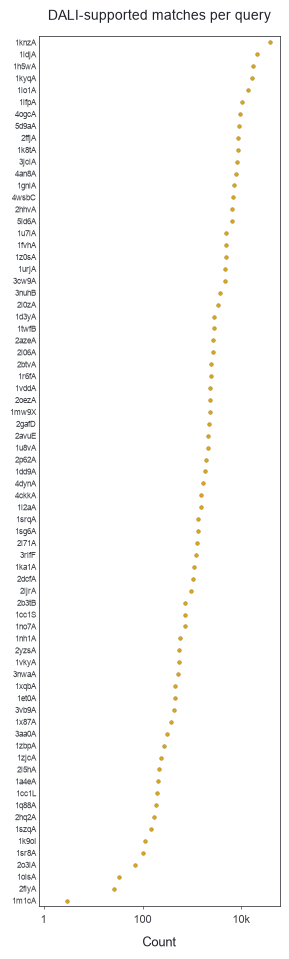

In [8]:
fig, ax = plt.subplots(figsize=(3.6, 10))
fig.subplots_adjust(left=.28, right=.95, top=.95, bottom=.08)
panel_a(ax, atlas, FS)
ax.set_title('DALI-supported matches per query', fontsize=FS['title'], pad=12)
save_panel(fig, 'a')


### Panel b: DALI score margins


Saved panel b to results/dali_prefiltering/fig4


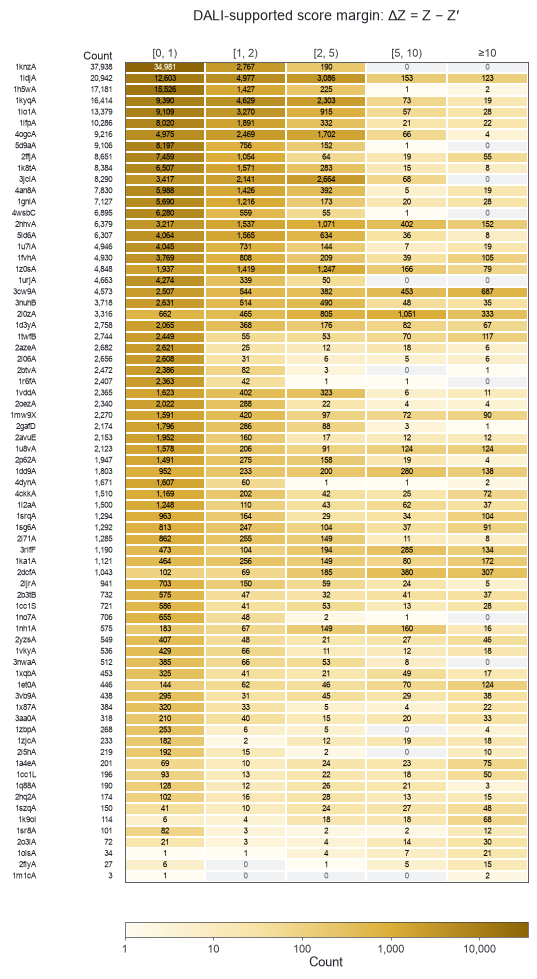

In [9]:
fig = plt.figure(figsize=(6.2, 10))
ax = fig.add_axes([.30, .10, .65, .82])
cax = fig.add_axes([.30, .045, .65, .015])
panel_b(ax, cax, atlas, FS, count_x=.28)
# Include query labels so this panel can be read independently of panel a.
for i, query in enumerate(atlas['query']):
    ax.text(-.22, i, query, transform=ax.get_yaxis_transform(), ha='right',
            va='center', fontsize=FS['row'], clip_on=False)
ax.set_title('DALI-supported score margin: ΔZ = Z − Z′', fontsize=FS['title'], pad=30)
save_panel(fig, 'b')


### Panel c: Mean recovery with bootstrap confidence intervals


Saved panel c to results/dali_prefiltering/fig4


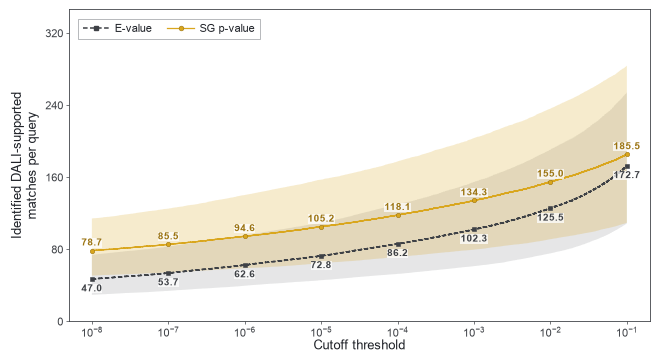

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
fig.subplots_adjust(left=.14, bottom=.17, right=.97, top=.95)
plot_recovery(ax, agg_frames, FS, ci=True, mean=True)
ax.set_ylabel('Identified DALI-supported\nmatches per query', fontsize=FS['label'])
curve_legend(ax, FS, 'upper left', (.015, .97))
save_panel(fig, 'c')


### Panel d: Recovery for the example query


Saved panel d to results/dali_prefiltering/fig4


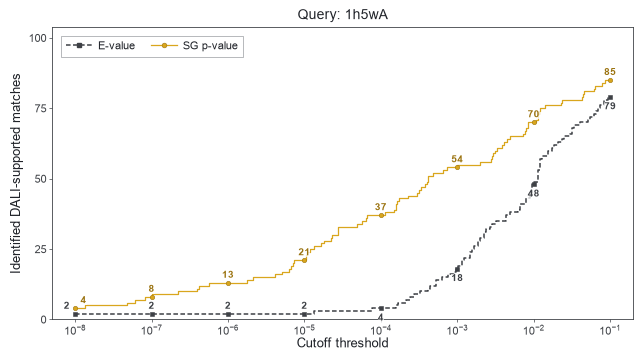

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
fig.subplots_adjust(left=.14, bottom=.17, right=.97, top=.90)
plot_recovery(ax, all_curves[EXAMPLE], FS)
ax.set_ylabel('Identified DALI-supported matches', fontsize=FS['label'])
ax.set_title(f'Query: {EXAMPLE}', fontsize=FS['title'])
curve_legend(ax, FS, 'upper left', (.015, .97))
save_panel(fig, 'd')


### Panel e: Matches found only by SG p-value


Saved panel e to results/dali_prefiltering/fig4


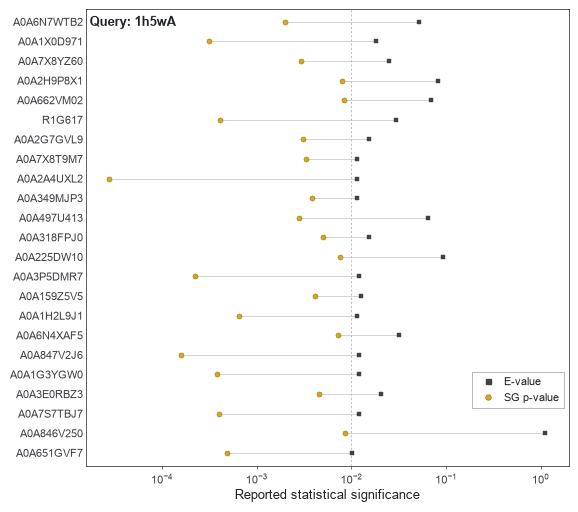

In [12]:
fig, ax = plt.subplots(figsize=(7, 5.5))
fig.subplots_adjust(left=.28, bottom=.13, right=.97, top=.96)
panel_e(ax, rescued, FS, EXAMPLE)
save_panel(fig, 'e')


## 4. Values plotted in each panel

In [13]:
cc = COUNT_COLS
panel_tables = {
    'a_positives_per_query': atlas[['query', 'label_positive', 'Zprime']].rename(columns={'label_positive': 'n_dali_supported'}),
    'b_margin_bin_counts': atlas.rename(columns=dict(zip(cc, BIN_LABELS))),
    'c_aggregate_curve': pd.concat([agg_frames[m].assign(metric=m) for m in METRICS], ignore_index=True)
        [['metric', 'cutoff', 'true_hits', 'ci_lower', 'ci_upper', 'total']].rename(columns={'true_hits': 'mean_per_query', 'total': 'pooled_total'}),
    'c_paired_difference': agg_diff,
    f'd_{EXAMPLE}_curve': pd.concat([all_curves[EXAMPLE][m] for m in METRICS], ignore_index=True),
    f'e_{EXAMPLE}_sg_only': rescued,
}
for k, v in panel_tables.items():
    v.to_csv(OUT / f'fig4_{k}.csv', index=False)
print('Wrote', len(panel_tables), 'CSVs to', OUT)
c_dec = panel_tables['c_aggregate_curve']; c_dec = c_dec[c_dec.cutoff.isin(TICKS)]
c_dec.pivot(index='cutoff', columns='metric', values=['mean_per_query', 'ci_lower', 'ci_upper']).round(2)

Wrote 6 CSVs to results/dali_prefiltering/fig4


mean_per_query         ci_lower         ci_upper        
metric               evalue  sgpval   evalue  sgpval   evalue  sgpval
cutoff                                                               
1.000000e-08          47.04   78.68    29.52   50.92    73.90  114.27
1.000000e-07          53.70   85.49    33.97   54.34    83.16  125.22
1.000000e-06          62.63   94.58    39.70   59.15    95.15  140.34
1.000000e-05          72.82  105.15    45.82   64.70   109.70  157.40
1.000000e-04          86.23  118.08    52.89   71.66   130.27  177.55
1.000000e-03         102.26  134.32    61.41   79.68   154.81  203.66
1.000000e-02         125.52  155.04    75.57   91.31   190.45  236.22
1.000000e-01         172.73  185.47   108.77  109.62   254.18  283.84